# 3.0 Prueba P2 (Clasificación): Riesgo de Déficit o Excedente en Estaciones

**Objetivo:** Definir y sustentar la aproximación del riesgo de que una estación se quede sin bicicletas (`deficit`) o sin anclajes (`excedente`) en las próximas **3 horas** a partir del flujo neto y la capacidad de cada estación (`references/ml-canvas.md`), y evaluar el baseline semanal (`lag_168h`) frente al modelo candidato `HistGradientBoostingClassifier`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score, precision_score, recall_score

from mi_bici.config import PROCESSED_DATA_DIR

# Constantes alineadas con references/ml-canvas.md
RANDOM_SEED = 42
TOP_N_STATIONS = 50       # Top 50 estaciones activas de mayor demanda en Train
HORIZON_HOURS = 3         # Ventana de anticipación operativa para cuadrillas de rebalanceo (3 horas)
THRESHOLD = 0.30          # ±30% de la capacidad de la estación en 3 horas
LAGS_HOURS = (24, 168, 336)  # 1 día (24h), 7 días (168h) y 14 días (336h)

trips = pd.read_parquet(PROCESSED_DATA_DIR / 'trips.parquet')
stations = pd.read_parquet(PROCESSED_DATA_DIR / 'stations.parquet')

2026-10-18 23:23:04.858 | INFO     | mi_bici.config:<module>:11 - PROJ_ROOT path is: /Users/poncho_stark/Documents/Tec/4to-tri/mlops/TC5061-Proyecto-Equipo11


## 1. Construcción del flujo horario y sustento de parámetros (`TOP_N_STATIONS = 50`, `HORIZON_HOURS = 3`, `THRESHOLD = 0.30`)
Como los datos abiertos no incluyen el inventario minuto a minuto, aproximamos el riesgo midiendo el **flujo neto acumulado en las siguientes 3 horas** (`arrivals - departures`) relativo a la capacidad (`capacity`) de cada estación:
- **¿Por qué un horizonte de `3 horas`?** Suponemos que es el margen que necesita el equipo de rebalanceo para despachar una camioneta y llegar a la estación antes de que quede vacía o llena; MiBici no publica ese dato.
- **¿Por qué las `50` estaciones de mayor flujo?** Evaluamos primero qué porcentaje de la demanda del sistema concentran en `Train` (`2024–2025`), evitando incluir estaciones periféricas donde el flujo por hora es cercano a cero.

In [2]:
# Seleccionar las 50 estaciones activas con más actividad en Train (2024-2025)
active_stations = stations.loc[stations['is_active'] & (stations['capacity'] > 0), ['station_id', 'capacity', 'zone']].copy()
train_trips = trips[trips['start_time'] <= '2025-12-31 23:59:59']
top_stations = (
    train_trips[train_trips['origin_id'].isin(active_stations['station_id'])]
    .groupby('origin_id')
    .size()
    .nlargest(TOP_N_STATIONS)
    .index
)

trips_sub = trips[trips['origin_id'].isin(top_stations) | trips['destination_id'].isin(top_stations)].copy()
trips_sub['dep_hour'] = trips_sub['start_time'].dt.floor('h')
trips_sub['arr_hour'] = trips_sub['end_time'].dt.floor('h')

deps = (
    trips_sub[trips_sub['origin_id'].isin(top_stations)]
    .groupby(['origin_id', 'dep_hour'], as_index=False)
    .size()
    .rename(columns={'origin_id': 'station_id', 'dep_hour': 'hour_ts', 'size': 'departures'})
)
arrs = (
    trips_sub[trips_sub['destination_id'].isin(top_stations)]
    .groupby(['destination_id', 'arr_hour'], as_index=False)
    .size()
    .rename(columns={'destination_id': 'station_id', 'arr_hour': 'hour_ts', 'size': 'arrivals'})
)

all_hours = pd.date_range(trips['start_time'].min().floor('h'), trips['start_time'].max().floor('h'), freq='h')
grid = pd.MultiIndex.from_product([top_stations, all_hours], names=['station_id', 'hour_ts']).to_frame().reset_index(drop=True)

df_p2 = (
    grid.merge(deps, on=['station_id', 'hour_ts'], how='left')
    .merge(arrs, on=['station_id', 'hour_ts'], how='left')
    .merge(active_stations, on='station_id', how='left')
)
df_p2['departures'] = df_p2['departures'].fillna(0.0)
df_p2['arrivals'] = df_p2['arrivals'].fillna(0.0)
df_p2['net_flow'] = df_p2['arrivals'] - df_p2['departures']
df_p2 = df_p2.sort_values(['station_id', 'hour_ts']).reset_index(drop=True)

# Flujo neto futuro en las próximas 3 horas (t+1, t+2, t+3) para construir la etiqueta
grp_flow = df_p2.groupby('station_id')['net_flow']
df_p2['future_3h_net_flow'] = grp_flow.shift(-1) + grp_flow.shift(-2) + grp_flow.shift(-3)
df_p2['pressure_ratio'] = df_p2['future_3h_net_flow'] / df_p2['capacity']

# Umbral de 30% de la capacidad de la estación en 3 horas
df_p2['risk_class'] = 'balanceado'
df_p2.loc[df_p2['pressure_ratio'] <= -THRESHOLD, 'risk_class'] = 'deficit'
df_p2.loc[df_p2['pressure_ratio'] >= THRESHOLD, 'risk_class'] = 'excedente'

print('Distribución de clases de riesgo (horizonte 3h):')
print(df_p2['risk_class'].value_counts(normalize=True).round(4))

Distribución de clases de riesgo (horizonte 3h):
risk_class
balanceado    0.7695
excedente     0.1192
deficit       0.1113
Name: proportion, dtype: float64


In [3]:
# Sustento empírico de TOP_N_STATIONS = 50 y del umbral THRESHOLD = 0.30
station_vol_train = (
    train_trips[train_trips['origin_id'].isin(active_stations['station_id'])]
    .groupby('origin_id')
    .size()
    .sort_values(ascending=False)
)
top50_share = station_vol_train.head(TOP_N_STATIONS).sum() / station_vol_train.sum() * 100
print(f'Participación de las Top {TOP_N_STATIONS} estaciones (10.6% de la red activa) en viajes de Train: {top50_share:.2f}%')
print(f'Promedio diario en Top {TOP_N_STATIONS}: {station_vol_train.head(TOP_N_STATIONS).mean() / 731:.1f} viajes/día vs. resto: {station_vol_train.iloc[TOP_N_STATIONS:].mean() / 731:.1f} viajes/día')

# Sensibilidad del umbral de presión (pressure_ratio) sobre la distribución de clases
pd.DataFrame([
    {
        'Umbral (THRESHOLD)': f'±{int(th * 100)}% capacidad ({th:.2f})',
        'deficit (%)': round(float((df_p2['pressure_ratio'] <= -th).mean() * 100), 2),
        'balanceado (%)': round(float(((df_p2['pressure_ratio'] > -th) & (df_p2['pressure_ratio'] < th)).mean() * 100), 2),
        'excedente (%)': round(float((df_p2['pressure_ratio'] >= th).mean() * 100), 2),
        'Total alertas críticas (%)': round(float(((df_p2['pressure_ratio'] <= -th) | (df_p2['pressure_ratio'] >= th)).mean() * 100), 2),
    }
    for th in [0.20, 0.30, 0.40]
])

Participación de las Top 50 estaciones (10.6% de la red activa) en viajes de Train: 37.15%
Promedio diario en Top 50: 93.3 viajes/día vs. resto: 24.6 viajes/día


,Umbral (THRESHOLD),deficit (%),balanceado (%),excedente (%),Total alertas críticas (%)
0,±20% capacidad (0.20),18.49,62.56,18.94,37.44
1,±30% capacidad (0.30),11.13,76.95,11.92,23.05
2,±40% capacidad (0.40),7.28,84.60,8.12,15.40


**Justificación de los números elegidos en P2 (`references/ml-canvas.md`):**
1. **`TOP_N_STATIONS = 50`:** Tan solo 50 estaciones (`10.6%` del catálogo activo) concentran el **`37.15%` de todos los viajes** del sistema (`93.3` viajes/día en promedio vs. `24.6` en el resto), siendo los nodos donde realmente ocurren emergencias horarias de vaciamiento o saturación.
2. **`THRESHOLD = 0.30` (30% de `dpcapacity` en 3 horas):** En una estación mediana de 15 anclajes, $\pm 30\%$ equivale a perder o ganar $\ge 5$ bicicletas netas en 3 horas. La tabla de sensibilidad muestra que un umbral de `0.20` dispararía alertas en el `37.44%` de las horas (saturando la capacidad de respuesta de las camionetas), mientras que `0.40` reduciría las alertas a `15.40%` (dejando estaciones sin atender). El valor **`0.30`** equilibra operativamente la detección en **`23.05%` de horas críticas** (`11.13%` `deficit` y `11.92%` `excedente`) frente a `76.95%` `balanceado`.

## 2. Variables predictoras pasadas (`last_3h`, `24h`, `168h`, `336h`) y partición temporal
Construimos las variables usando únicamente datos hasta la hora $t$: el flujo reciente de las **últimas 3 horas** ($t-2, t-1, t$, que captura si la estación ya se está vaciando o llenando en este momento) y la presión observada en esa misma ventana de 3 horas hace **1 día (`24h`)**, **7 días (`168h`, 1 semana)** y **14 días (`336h`, 2 semanas)**. Todas estas horas son estrictamente anteriores a $t$.

In [4]:
grp_fut3h = df_p2.groupby('station_id')['future_3h_net_flow']
df_p2['net_flow_last_3h'] = grp_flow.rolling(3).sum().reset_index(level=0, drop=True)
df_p2['pressure_last_3h'] = df_p2['net_flow_last_3h'] / df_p2['capacity']
df_p2['pressure_window_lag_24h'] = grp_fut3h.shift(24) / df_p2['capacity']
df_p2['pressure_window_lag_168h'] = grp_fut3h.shift(168) / df_p2['capacity']
df_p2['pressure_window_lag_336h'] = grp_fut3h.shift(336) / df_p2['capacity']
df_p2['risk_lag_168h'] = df_p2.groupby('station_id')['risk_class'].shift(168)

df_p2['hour'] = df_p2['hour_ts'].dt.hour
df_p2['day_of_week'] = df_p2['hour_ts'].dt.dayofweek
df_p2['is_weekend'] = (df_p2['day_of_week'] >= 5).astype(int)

df_p2 = df_p2.dropna(
    subset=[
        'future_3h_net_flow',
        'pressure_last_3h',
        'pressure_window_lag_24h',
        'pressure_window_lag_168h',
        'pressure_window_lag_336h',
        'risk_lag_168h',
    ]
).reset_index(drop=True)

train_p2 = df_p2[df_p2['hour_ts'] <= '2025-12-31 23:00:00'].copy()
val_p2 = df_p2[(df_p2['hour_ts'] >= '2026-01-01 00:00:00') & (df_p2['hour_ts'] <= '2026-06-30 23:00:00')].copy()
test_p2 = df_p2[df_p2['hour_ts'] >= '2026-07-01 00:00:00'].copy()

print(f'Train P2: {len(train_p2):,} | Val P2: {len(val_p2):,} | Test P2: {len(test_p2):,}')

Train P2: 860,400 | Val P2: 217,200 | Test P2: 110,250


## 3. Evaluación: Regla Semanal (Baseline) vs. HistGradientBoostingClassifier
Comparamos el baseline histórico (predecir la misma clase observada hace 7 días a esa misma hora) contra un modelo candidato `HistGradientBoostingClassifier` que combina la tendencia de las últimas 3 horas con los patrones de hace 1, 7 y 14 días.

In [5]:
feature_cols = [
    'hour',
    'day_of_week',
    'is_weekend',
    'departures',
    'arrivals',
    'net_flow',
    'pressure_last_3h',
    'pressure_window_lag_24h',
    'pressure_window_lag_168h',
    'pressure_window_lag_336h',
    'capacity',
]
labels_order = ['deficit', 'balanceado', 'excedente']


def eval_clf(y_true, y_pred, prefix: str) -> dict[str, float]:
    return {
        f'{prefix}_f1_macro': round(float(f1_score(y_true, y_pred, average='macro')), 4),
        f'{prefix}_recall_macro': round(float(recall_score(y_true, y_pred, average='macro')), 4),
        f'{prefix}_precision_macro': round(float(precision_score(y_true, y_pred, average='macro')), 4),
    }


base_val_p2 = eval_clf(val_p2['risk_class'], val_p2['risk_lag_168h'], 'val')
base_test_p2 = eval_clf(test_p2['risk_class'], test_p2['risk_lag_168h'], 'test')

clf_model = HistGradientBoostingClassifier(
    max_iter=150, learning_rate=0.08, max_depth=6, random_state=RANDOM_SEED
)
clf_model.fit(train_p2[feature_cols], train_p2['risk_class'])

pred_val_gb = clf_model.predict(val_p2[feature_cols])
pred_test_gb = clf_model.predict(test_p2[feature_cols])

gb_val_p2 = eval_clf(val_p2['risk_class'], pred_val_gb, 'val')
gb_test_p2 = eval_clf(test_p2['risk_class'], pred_test_gb, 'test')

pd.DataFrame([
    {'modelo': 'Baseline (Misma clase hace 7 días)', **base_val_p2, **base_test_p2},
    {'modelo': 'Candidato (HistGradientBoosting)', **gb_val_p2, **gb_test_p2},
])

,modelo,val_f1_macro,val_recall_macro,val_precision_macro,test_f1_macro,test_recall_macro,test_precision_macro
0,Baseline (Misma clase hace 7 días),0.5666,0.5658,0.5673,0.5884,0.5865,0.5903
1,Candidato (HistGradientBoosting),0.5969,0.5384,0.7407,0.6142,0.5535,0.7598


El `HistGradientBoostingClassifier` mejora al baseline semanal en `F1-macro` y sobre todo en `Precision-macro`, pero su `Recall-macro` queda por debajo del baseline: predice menos falsas alarmas a cambio de dejar pasar más casos de riesgo. A continuación graficamos las matrices de confusión en el conjunto de prueba (`Test`).

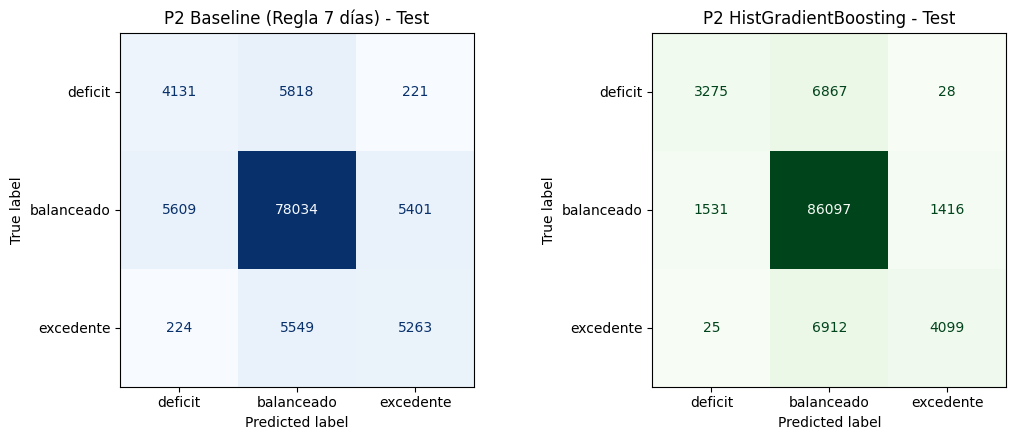

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

cm_base = confusion_matrix(test_p2['risk_class'], test_p2['risk_lag_168h'], labels=labels_order)
ConfusionMatrixDisplay(cm_base, display_labels=labels_order).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('P2 Baseline (Regla 7 días) - Test')

cm_gb = confusion_matrix(test_p2['risk_class'], pred_test_gb, labels=labels_order)
ConfusionMatrixDisplay(cm_gb, display_labels=labels_order).plot(ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title('P2 HistGradientBoosting - Test')

plt.tight_layout()
plt.show()

### Conclusiones
- El riesgo se aproxima con la razón entre el flujo neto de las próximas 3 horas (`arrivals - departures`) y la capacidad (`dpcapacity`): `deficit` si la pérdida neta supera el 30% de la capacidad y `excedente` si la ganancia neta supera el 30%.
- Las 50 estaciones de mayor demanda en `Train` (10.6% de las activas) concentran el `37.15%` de los viajes (`93.3` viajes/día contra `24.6` del resto), por eso P2 se limita a ellas.
- Con el umbral `0.30`, el `23.05%` de las horas es crítico (`11.13%` `deficit` y `11.92%` `excedente`). Con `0.20` las alertas subirían a `37.44%` y con `0.40` bajarían a `15.40%`.
- Para el equipo de rebalanceo es más caro no detectar una estación que se va a vaciar o llenar que revisar una de más, por eso el recall de las clases de riesgo importa.
- HGB gana en `F1-macro` y `Precision-macro`, pero pierde en `Recall-macro` contra la regla de 7 días. Falta probar `class_weight` o ajustar el umbral de decisión para subir el recall.

Siguiente paso: mover la construcción de variables a `mi_bici/features.py` y registrar los dos modelos en MLflow con su matriz de confusión como artefacto.